# 05 – P2: robustez a dados degradados (detecção sem rótulos)

**Pergunta (P2):** como a detecção se comporta quando os dados chegam piores, e qual decisão de engenharia (a cobertura mínima das janelas) protege ou prejudica?

**Desenho**
- A degradação é aplicada a uma **cópia** da Silver de 1 min; a base original não é alterada.
- **Cenários:** minutos ausentes (10% e 30%, aleatórios e independentes) e ruído gaussiano nos analógicos (0,1 e 0,3 desvio-padrão do período de treino), com **5 sementes** por cenário. A referência sem degradação roda uma vez.
- **Configurações** (escolhidas antes de rodar a P2, a partir dos resultados do notebook 04; são **exploratórias**, porque a seleção de só analógicos foi pós-hoc):
  1. `E1-A IF`: Isolation Forest, 1 min, só analógicos, sem janelas (detecção rápida).
  2. `E2-A Mah (cob 80%)`: Mahalanobis, janelas de 1 h e 6 h, cobertura mínima de 80%.
  3. `E2-A Mah (cob 50%)`: o mesmo, com cobertura mínima de 50% (a decisão de engenharia sob teste).
- **Limiar:** percentil 99,9 da validação **do dado degradado** (como seria na prática). Treino, validação e teste usam as mesmas datas do notebook 04.
- **Avaliação na população original:** os mesmos minutos de teste da E2-A sem degradação. Minuto sem dado (removido, ou sem cobertura na janela) **não pode gerar alarme**: conta como "sem alarme". Assim, perder dados penaliza a detecção, como na prática.

Com 4 eventos, os resultados são descritivos. O desvio entre sementes mostra a variabilidade da degradação, não significância.

In [1]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

import config
from degradation import add_noise, drop_minutes
from detection import (
    anomaly_scores, evaluate_detection, in_failure, post_failure_mask, window_features,
)

# --- Parâmetros ---------------------------------------------------------------
WINDOWS = [60, 360]
TRAIN_FRACTION = 0.7
VAL_MARGIN_DAYS = 1
EMBARGO_H = 24
QUANTILE = 99.9              # quantil de referência (definido antes de ver o teste)
SUSTAINED_RECALL = 0.10
N_SEEDS = 5
MISSING_LEVELS = [0.10, 0.30]
NOISE_LEVELS = [0.1, 0.3]    # múltiplos do desvio-padrão do treino
SEED = config.SEED

CONFIGS = {
    "E1-A IF": dict(model="IsolationForest", windows=[], coverage=None),
    "E2-A Mah (cob 80%)": dict(model="Mahalanobis", windows=WINDOWS, coverage=0.8),
    "E2-A Mah (cob 50%)": dict(model="Mahalanobis", windows=WINDOWS, coverage=0.5),
}


## 1. Dados, divisão e população de referência

In [2]:
rep = pd.read_csv(config.FAILURE_REPORT, parse_dates=["start_time", "end_time"]).sort_values("start_time")
failures = [
    {"id": int(r.failure_id), "start": r.start_time.to_pydatetime(), "end": r.end_time.to_pydatetime()}
    for r in rep.itertuples()
]

silver_dir = config.SILVER_DIR / "e1"
groups = json.loads((silver_dir / "_columns.json").read_text(encoding="utf-8"))
analog = groups["analog"]
sil1 = pd.read_parquet(silver_dir)
sil1["ts"] = pd.to_datetime(sil1["ts"]).dt.tz_localize(None)
sil1 = sil1.sort_values("ts").reset_index(drop=True)
sil1 = sil1[["ts", "n_readings"] + analog]          # P2 usa só analógicos

label_map = pd.Series(in_failure(sil1["ts"], failures), index=sil1["ts"])
excl_map = pd.Series(post_failure_mask(sil1["ts"], failures, EMBARGO_H), index=sil1["ts"])

t0, f1 = sil1["ts"].min(), pd.Timestamp(failures[0]["start"])
train_end = (t0 + (f1 - t0) * TRAIN_FRACTION).floor("D")
val_end = (f1 - pd.Timedelta(days=VAL_MARGIN_DAYS)).floor("D")
ref_std = sil1.loc[sil1["ts"] < train_end, analog].std()        # escala do ruído
print("Treino:", t0, "->", train_end, "| Validação ->", val_end, "| Teste até", sil1["ts"].max())

# População de referência: minutos de teste da E2-A sem degradação (cobertura 80%), fora da recuperação pós-falha
base_feat = window_features(sil1, analog, [], WINDOWS, 0.8)
ref = base_feat.loc[base_feat["coverage_ok"] & (base_feat["ts"] >= val_end), ["ts"]].copy()
ref = ref[~ref["ts"].map(excl_map).astype(bool)].reset_index(drop=True)
ref["label"] = ref["ts"].map(label_map).astype(int)
print(f"Minutos de referência: {len(ref):,} | em falha: {int(ref.label.sum()):,}")

Treino: 2020-02-01 00:00:00 -> 2020-03-25 00:00:00 | Validação -> 2020-04-17 00:00:00 | Teste até 2020-09-01 03:59:00
Minutos de referência: 133,446 | em falha: 4,620


## 2. Execução de uma configuração sobre um conjunto de dados

In [3]:
def build(sil, windows, coverage):
    if not windows:
        return sil[["ts"] + analog], list(analog)
    feat = window_features(sil, analog, [], windows, coverage)
    feat = feat[feat["coverage_ok"]].drop(columns="coverage_ok")
    return feat, [c for c in feat.columns if c != "ts"]

EMPTY = {  # pipeline sem dados suficientes para ajustar o modelo: nenhuma detecção possível
    "eventos_detectados": 0, "eventos_sustentados": 0, "recall_medio": 0.0, "atraso_mediano_h": np.nan,
    "falsos_alarmes_por_dia": 0.0, "frac_normais_em_alarme": 0.0, "pr_auc": np.nan,
    "minutos_de_referencia_com_score": 0.0,
}

def run(sil, cfg):
    frame, feats = build(sil, cfg["windows"], cfg["coverage"])
    tr = frame[frame["ts"] < train_end]
    va = frame[(frame["ts"] >= train_end) & (frame["ts"] < val_end)]
    te = frame[frame["ts"] >= val_end]
    if len(tr) < 100 or len(va) < 100:
        return dict(EMPTY)                                       # dados insuficientes para ajustar
    sc = anomaly_scores(cfg["model"], tr[feats], {"val": va[feats], "test": te[feats]}, seed=SEED)
    thr = float(np.quantile(sc["val"], QUANTILE / 100))
    scored = pd.DataFrame({"ts": te["ts"].to_numpy(), "score": sc["test"]})
    t = ref.merge(scored, on="ts", how="left")
    cobertura_scores = t["score"].notna().mean()
    t["score"] = t["score"].fillna(t["score"].min() - 1.0)      # sem dado = sem alarme
    ev, g = evaluate_detection(t, thr, failures)
    pr = average_precision_score(t["label"], t["score"]) if t["label"].sum() else np.nan
    return {
        "eventos_detectados": int(ev["detectada"].sum()),
        "eventos_sustentados": int((ev["recall_minutos"] >= SUSTAINED_RECALL).sum()),
        "recall_medio": ev["recall_minutos"].mean(),
        "atraso_mediano_h": ev["atraso_h"].median(),
        "falsos_alarmes_por_dia": g["falsos_alarmes_por_dia"],
        "frac_normais_em_alarme": g["frac_minutos_normais_em_alarme"],
        "pr_auc": pr,
        "minutos_de_referencia_com_score": cobertura_scores,
    }

## 3. Referência sem degradação e cenários degradados

In [4]:
rows = []
for name, cfg in CONFIGS.items():
    r = run(sil1, cfg)
    rows.append({"config": name, "cenario": "base", "nivel": 0.0, "semente": 0, **r})
    print(name, "| referência:", {k: round(v, 3) if isinstance(v, float) else v for k, v in r.items()})

SCENARIOS = [("faltantes", lv) for lv in MISSING_LEVELS] + [("ruido", lv) for lv in NOISE_LEVELS]
for kind, level in SCENARIOS:
    for seed in range(N_SEEDS):
        if kind == "faltantes":
            deg = drop_minutes(sil1, level, seed=1000 + seed)
        else:
            deg = add_noise(sil1, analog, level, ref_std, seed=1000 + seed)
        for name, cfg in CONFIGS.items():
            r = run(deg, cfg)
            rows.append({"config": name, "cenario": kind, "nivel": level, "semente": seed, **r})
    print("cenário concluído:", kind, level)

res = pd.DataFrame(rows)

E1-A IF | referência: {'eventos_detectados': 3, 'eventos_sustentados': 2, 'recall_medio': np.float64(0.49), 'atraso_mediano_h': np.float64(0.333), 'falsos_alarmes_por_dia': 0.335, 'frac_normais_em_alarme': 0.015, 'pr_auc': 0.58, 'minutos_de_referencia_com_score': np.float64(1.0)}
E2-A Mah (cob 80%) | referência: {'eventos_detectados': 3, 'eventos_sustentados': 3, 'recall_medio': np.float64(0.528), 'atraso_mediano_h': np.float64(3.967), 'falsos_alarmes_por_dia': 0.022, 'frac_normais_em_alarme': 0.013, 'pr_auc': 0.608, 'minutos_de_referencia_com_score': np.float64(1.0)}
E2-A Mah (cob 50%) | referência: {'eventos_detectados': 3, 'eventos_sustentados': 3, 'recall_medio': np.float64(0.53), 'atraso_mediano_h': np.float64(3.933), 'falsos_alarmes_por_dia': 0.022, 'frac_normais_em_alarme': 0.013, 'pr_auc': 0.608, 'minutos_de_referencia_com_score': np.float64(1.0)}
cenário concluído: faltantes 0.1
cenário concluído: faltantes 0.3
cenário concluído: ruido 0.1
cenário concluído: ruido 0.3


## 4. Resultados

Para cada configuração e cenário: média e desvio-padrão entre as 5 sementes. `minutos_de_referencia_com_score` é a fração dos minutos de teste que ainda geram score (o restante não pode alarmar). Se a degradação deixa o pipeline sem dados suficientes para ajustar o modelo (por exemplo, cobertura de 80% com muitos minutos removidos), a detecção é **zero** por construção: aparece como 0 eventos e 0 de cobertura de scores.

In [5]:
metrics = ["eventos_sustentados", "recall_medio", "falsos_alarmes_por_dia", "frac_normais_em_alarme",
           "pr_auc", "minutos_de_referencia_com_score"]
summ = res.groupby(["config", "cenario", "nivel"])[metrics].agg(["mean", "std"]).round(3)
summ

eventos_sustentados        recall_medio  \
                                                  mean    std         mean   
config             cenario   nivel                                           
E1-A IF            base      0.0                   2.0    NaN        0.490   
                   faltantes 0.1                   1.0  0.000        0.205   
                             0.3                   1.6  0.548        0.231   
                   ruido     0.1                   2.0  0.000        0.383   
                             0.3                   2.0  0.000        0.217   
E2-A Mah (cob 50%) base      0.0                   3.0    NaN        0.530   
                   faltantes 0.1                   3.0  0.000        0.476   
                             0.3                   3.0  0.000        0.370   
                   ruido     0.1                   3.0  0.000        0.525   
                             0.3                   3.0  0.000        0.511   
E2-A Mah (cob 80%) base      0.0                   3.0    NaN        0.528   
                   faltantes 0.1                   3.0  0.000        0.446   
                             0.3                   0.0  0.000        0.000   
                   ruido     0.1                   3.0  0.000        0.524   
                             0.3                   3.0  0.000        0.511   

                                          falsos_alarmes_por_dia         \
                                      std                   mean    std   
config             cenario   nivel                                        
E1-A IF            base      0.0      NaN                  0.335    NaN   
                   faltantes 0.1    0.031                  0.186  0.108   
                             0.3    0.083                  0.355  0.456   
                   ruido     0.1    0.089                  0.232  0.189   
                             0.3    0.037                  0.136  0.051   
E2-A Mah (cob 50%) base      0.0      NaN                  0.022    NaN   
                   faltantes 0.1    0.005                  0.022  0.000   
                             0.3    0.008                  0.022  0.000   
                   ruido     0.1    0.002                  0.022  0.000   
                             0.3    0.005                  0.022  0.000   
E2-A Mah (cob 80%) base      0.0      NaN                  0.022    NaN   
                   faltantes 0.1    0.005                  0.022  0.000   
                             0.3    0.000                  0.000  0.000   
                   ruido     0.1    0.002                  0.022  0.000   
                             0.3    0.004                  0.022  0.000   

                                   frac_normais_em_alarme        pr_auc  \
                                                     mean    std   mean   
config             cenario   nivel                                        
E1-A IF            base      0.0                    0.015    NaN  0.580   
                   faltantes 0.1                    0.013  0.000  0.490   
                             0.3                    0.011  0.001  0.397   
                   ruido     0.1                    0.015  0.000  0.559   
                             0.3                    0.013  0.001  0.532   
E2-A Mah (cob 50%) base      0.0                    0.013    NaN  0.608   
                   faltantes 0.1                    0.012  0.000  0.554   
                             0.3                    0.009  0.000  0.437   
                   ruido     0.1                    0.013  0.000  0.608   
                             0.3                    0.012  0.000  0.608   
E2-A Mah (cob 80%) base      0.0                    0.013    NaN  0.608   
                   faltantes 0.1                    0.012  0.000  0.509   
                             0.3                    0.000  0.000    NaN   
                   ruido     0.1                    0.013  0.000  0.609   
    

In [6]:
base = res[res["cenario"] == "base"].set_index("config")[metrics]
delta = res[res["cenario"] != "base"].groupby(["config", "cenario", "nivel"])[metrics].mean()
delta = delta - base.reindex(delta.index.get_level_values("config")).to_numpy()
print("Diferença em relação à referência sem degradação (média das sementes):")
delta.round(3)

Diferença em relação à referência sem degradação (média das sementes):


eventos_sustentados  recall_medio  \
config             cenario   nivel                                      
E1-A IF            faltantes 0.1                   -1.0        -0.285   
                             0.3                   -0.4        -0.259   
                   ruido     0.1                    0.0        -0.107   
                             0.3                    0.0        -0.273   
E2-A Mah (cob 50%) faltantes 0.1                    0.0        -0.053   
                             0.3                    0.0        -0.159   
                   ruido     0.1                    0.0        -0.004   
                             0.3                    0.0        -0.019   
E2-A Mah (cob 80%) faltantes 0.1                    0.0        -0.082   
                             0.3                   -3.0        -0.528   
                   ruido     0.1                    0.0        -0.004   
                             0.3                    0.0        -0.017   

                                    falsos_alarmes_por_dia  \
config             cenario   nivel                           
E1-A IF            faltantes 0.1                    -0.150   
                             0.3                     0.020   
                   ruido     0.1                    -0.103   
                             0.3                    -0.199   
E2-A Mah (cob 50%) faltantes 0.1                     0.000   
                             0.3                     0.000   
                   ruido     0.1                     0.000   
                             0.3                     0.000   
E2-A Mah (cob 80%) faltantes 0.1                     0.000   
                             0.3                    -0.022   
                   ruido     0.1                     0.000   
                             0.3                     0.000   

                                    frac_normais_em_alarme  pr_auc  \
config             cenario   nivel                                   
E1-A IF            faltantes 0.1                    -0.002  -0.090   
                             0.3                    -0.005  -0.183   
                   ruido     0.1                    -0.000  -0.021   
                             0.3                    -0.002  -0.048   
E2-A Mah (cob 50%) faltantes 0.1                    -0.001  -0.054   
                             0.3                    -0.004  -0.171   
                   ruido     0.1                    -0.000   0.001   
                             0.3                    -0.001   0.001   
E2-A Mah (cob 80%) faltantes 0.1                    -0.002  -0.100   
                             0.3                    -0.013     NaN   
                   ruido     0.1                    -0.000   0.000   
                             0.3                    -0.001   0.001   

                                    minutos_de_referencia_com_score  
config             cenario   nivel                                   
E1-A IF            faltantes 0.1                              -0.10  
                             0.3                              -0.30  
                   ruido     0.1                               0.00  
                             0.3                               0.00  
E2-A Mah (cob 50%) faltantes 0.1                              -0.10  
                             0.3                              -0.30  
                   ruido     0.1                               0.00  
                             0.3                               0.00  
E2-A Mah (cob 80%) faltantes 0.1                              -0.14  
                             0.3                              -1.00  
                   ruido     0.1                               0.00  
                             0.3                               0.00

## 5. Curvas de degradação

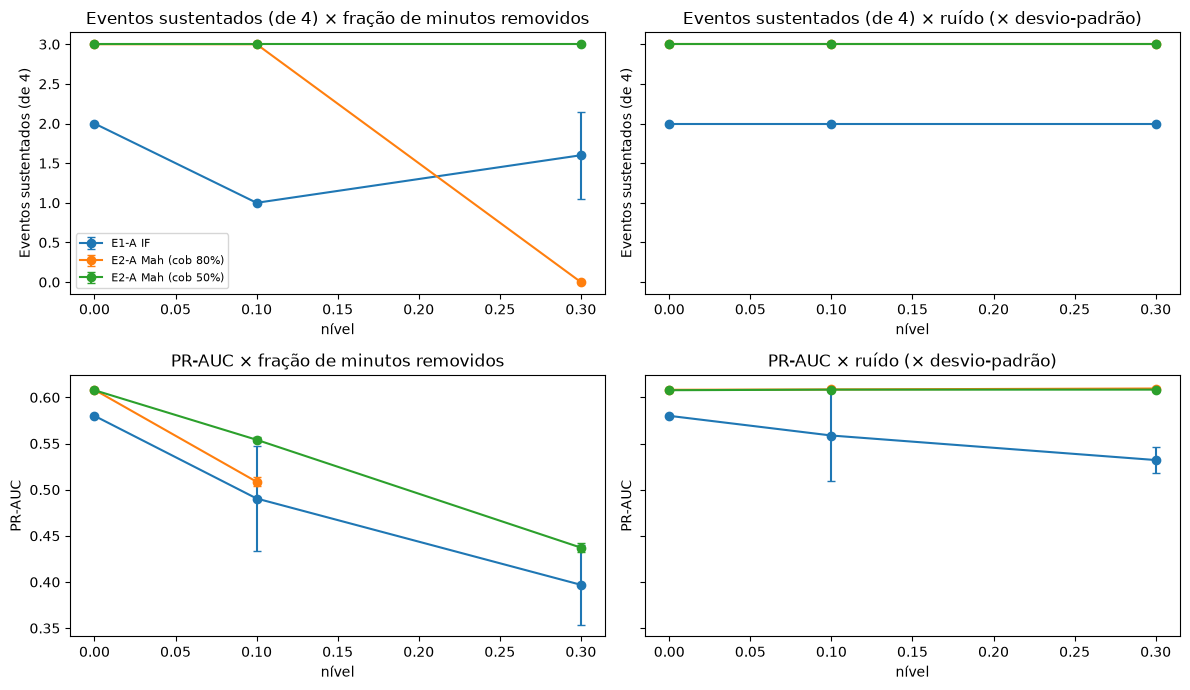

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey="row")
for j, kind in enumerate(["faltantes", "ruido"]):
    for i, (metric, label) in enumerate([("eventos_sustentados", "Eventos sustentados (de 4)"), ("pr_auc", "PR-AUC")]):
        ax = axes[i, j]
        for name in CONFIGS:
            b = base.loc[name, metric]
            d = res[(res.config == name) & (res.cenario == kind)].groupby("nivel")[metric].agg(["mean", "std"])
            x = [0.0] + list(d.index)
            y = [b] + list(d["mean"])
            e = [0.0] + list(d["std"].fillna(0))
            ax.errorbar(x, y, yerr=e, marker="o", capsize=3, label=name)
        ax.set_title(f"{label} × {'fração de minutos removidos' if kind == 'faltantes' else 'ruído (× desvio-padrão)'}")
        ax.set_xlabel("nível"); ax.set_ylabel(label)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
out = config.DOCS_DIR
out.mkdir(exist_ok=True)
res.to_csv(out / "resultados_p2_degradacao.csv", index=False)
summ.to_csv(out / "resultados_p2_degradacao_resumo.csv")
print("Resultados salvos em", out)

Resultados salvos em C:\workspace\Projeto-Integrador-CienciaDados-UTFPR\docs


- **Qual degrada mais a detecção?** Depende da configuração. O ruído gaussiano (até 0,3 desvio-padrão) quase não altera o E2-A Mahalanobis: ele mantém 3/4 eventos sustentados e recall médio perto de 0,51. Com minutos ausentes, o E2-A Mah (cob 80%) colapsa com 30% de remoção, por falta de dados para ajustar o modelo. A cobertura de 50% ainda mantém 3 eventos, mas o recall observado cai de 0,53 na referência para 0,48 com 10% de faltantes e 0,37 com 30%.
- **A queda de recall do E2-A Mah (cob 50%) é uma perda real de desempenho?** Quase toda a queda é mecânica: com 10% e 30% de faltantes, respectivamente 90% e 70% dos minutos de referência ainda têm score. Ajustando o recall pela fração com score, temos 0,48/0,90 ≈ 0,529 e 0,37/0,70 ≈ 0,529, praticamente igual ao recall de referência (0,53). Portanto, por minuto disponível, o desempenho não muda; a perda de detecção vem dos minutos que não existem.
- **A cobertura mínima de 50% protege contra minutos ausentes?** Sim, principalmente com 30% de faltantes: ao contrário da cobertura de 80%, que não consegue ajustar o modelo, a de 50% mantém 3/4 eventos sustentados e scores em cerca de 70% dos minutos. A fração de minutos normais em alarme cai de 1,3% para 0,9%, mas isso não é melhora: minutos sem dado não podem gerar alarme, então a queda também é mecânica. Com 10% de faltantes, as duas coberturas mantêm 3/4 eventos.
- **O Isolation Forest sem janelas é mais robusto que o Mahalanobis com janelas?** Não em todos os cenários. No E1-A IF, com apenas 10% de minutos removidos, o recall cai de 0,49 para 0,205 e os eventos sustentados caem de 2 para uma média de 1. Essa perda é maior do que o efeito mecânico esperado de remover 10% dos minutos. Com ruído, o IF mantém 2 eventos sustentados, mas o recall cai para 0,38 (ruído 0,1) e 0,22 (ruído 0,3). O E2-A Mah (cob 50%) é mais estável por minuto com score, mas sofre a perda mecânica quando minutos faltam; não há um vencedor geral para todas as degradações.
- **Variabilidade entre sementes:** aparece sobretudo no E1-A IF com 30% de faltantes: eventos sustentados variam (desvio-padrão 0,55), recall tem desvio-padrão 0,08 e falsos alarmes por dia variam bastante (desvio-padrão 0,46). O E2-A Mah com cobertura de 50% é mais estável: mantém 3 eventos sustentados nos cenários, com baixa dispersão de recall e PR-AUC. Para o Mahalanobis com cobertura de 80% e 30% de faltantes, o resultado é sempre zero porque não há dados suficientes para ajustar o modelo.
- **Cautela:** as configurações só com analógicos são exploratórias e foram escolhidas após observar resultados anteriores. Há apenas 4 eventos; portanto, estes resultados são descritivos, e a dispersão entre sementes mede a sensibilidade à amostra de minutos removidos, não significância estatística.